# Probe results visualization
Plots outputs from linear probes (age bins) and regression probes (confound features), plus feature-only baselines.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')


In [2]:
import os
os.chdir("/Users/tzl/repos/story-features")


## Find artifact files

In [3]:
ROOT = Path('.').resolve()

linear_probe_csvs = sorted(ROOT.glob('artifacts/**/probe_results.csv'))
# Support multiple output folder names
reg_probe_csvs = sorted([p for p in ROOT.glob('artifacts/**/probe_*.csv') if 'layerwise_regression_probe' in str(p.parent)])
feature_baselines = sorted(ROOT.glob('results/analysis/natural_language/feature_baseline/feature_baseline*.csv'))

print('linear probes:', len(linear_probe_csvs))
for p in linear_probe_csvs[:10]:
    print('  ', p)
print('regression probes:', len(reg_probe_csvs))
for p in reg_probe_csvs[:10]:
    print('  ', p)
print('feature baselines:', len(feature_baselines))
for p in feature_baselines[:10]:
    print('  ', p)


linear probes: 2
   /Users/tzl/repos/story-features/results/analysis/representation/probes/linear_probe/probe_results.csv
   /Users/tzl/repos/story-features/results/analysis/representation/probes/linear_probe_distilbert/probe_results.csv
regression probes: 6
   /Users/tzl/repos/story-features/results/analysis/representation/probes/layerwise_regression_probe/probe_avg_syllables_per_word.csv
   /Users/tzl/repos/story-features/results/analysis/representation/probes/layerwise_regression_probe/probe_flesch_kincaid_grade_est.csv
   /Users/tzl/repos/story-features/results/analysis/representation/probes/layerwise_regression_probe/probe_mean_log10_corpus_freq.csv
   /Users/tzl/repos/story-features/results/analysis/representation/probes/layerwise_regression_probe/probe_rare_frac_corpus_le_5.csv
   /Users/tzl/repos/story-features/results/analysis/representation/probes/layerwise_regression_probe/probe_ttr.csv
   /Users/tzl/repos/story-features/results/analysis/representation/probes/layerwise_regre

## Plot: age-bin linear probe (accuracy vs layer)

In [4]:
if not linear_probe_csvs:
    raise FileNotFoundError('No artifacts/**/probe_results.csv found. Run run_linear_probe.py first.')

# If multiple exist, pick the most recently modified
best = max(linear_probe_csvs, key=lambda p: p.stat().st_mtime)
dfp = pd.read_csv(best)
display(best)
dfp.head()

PosixPath('/Users/tzl/repos/story-features/results/analysis/representation/probes/linear_probe_distilbert/probe_results.csv')

,layer,n_train,n_test,n_classes,accuracy,f1_macro
0,0,1326,443,3,0.650113,0.571703
1,1,1326,443,3,0.659142,0.568714
2,2,1326,443,3,0.625282,0.537799
3,3,1326,443,3,0.623025,0.525569
4,4,1326,443,3,0.632054,0.544954


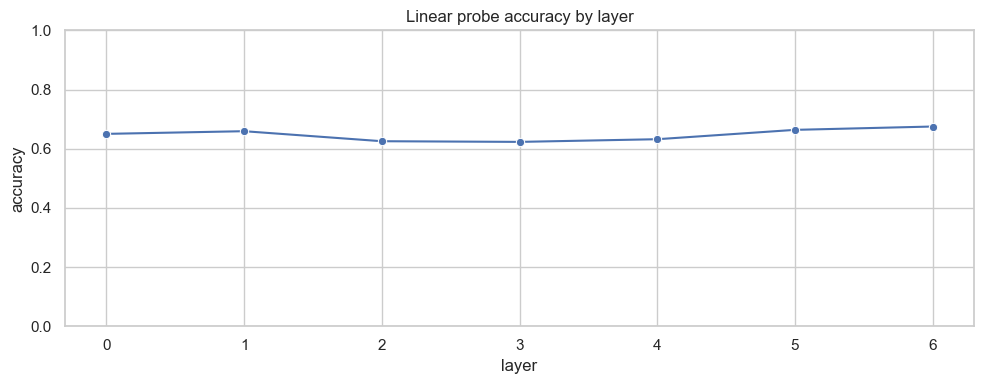

In [5]:
plt.figure(figsize=(10,4))
sns.lineplot(data=dfp, x='layer', y='accuracy', marker='o')
plt.title('Linear probe accuracy by layer')
plt.ylim(0, 1)
plt.tight_layout()


## Plot: regression probes (R² vs layer)

In [6]:
if reg_probe_csvs:
    # Load all and label by target name
    rows=[]
    for p in reg_probe_csvs:
        t = p.stem.replace('probe_','')
        d = pd.read_csv(p)
        d['target'] = t
        d['path'] = str(p)
        rows.append(d)
    reg = pd.concat(rows, ignore_index=True)
    reg.head()
else:
    reg = None
    print('No regression probe CSVs found (results/analysis/representation/probes/layerwise_regression_probe/probe_*.csv).')


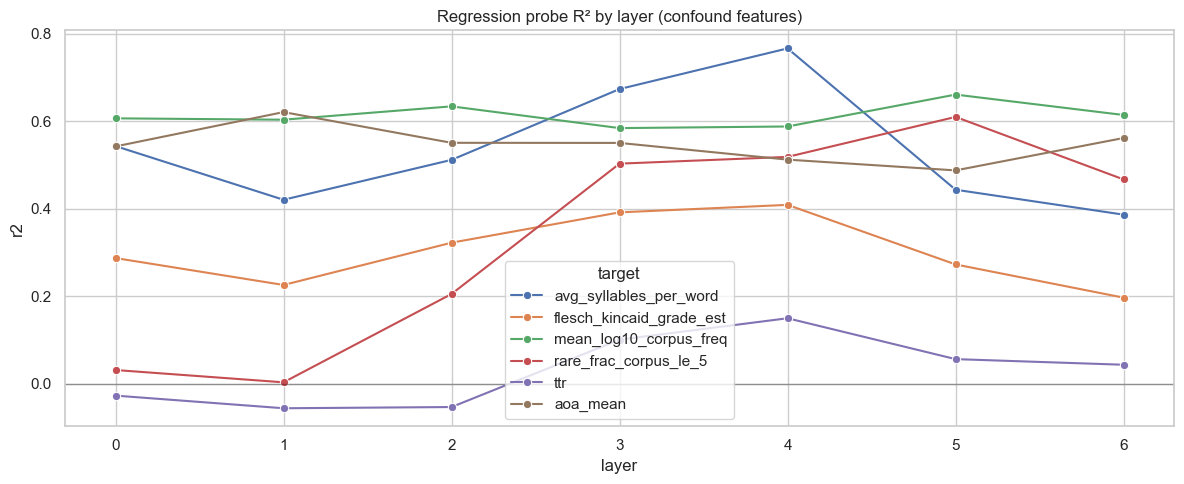

In [7]:
if reg is not None:
    plt.figure(figsize=(12,5))
    sns.lineplot(data=reg, x='layer', y='r2', hue='target', marker='o')
    plt.title('Regression probe R² by layer (confound features)')
    plt.axhline(0, color='black', lw=1, alpha=0.3)
    plt.tight_layout()


## Feature-only baseline (no activations)

In [8]:
if feature_baselines:
    fb = pd.concat([pd.read_csv(p).assign(path=str(p)) for p in feature_baselines], ignore_index=True)
    fb.sort_values('accuracy', ascending=False).head(20)
else:
    print('No results/analysis/natural_language/feature_baseline/feature_baseline*.csv found. Run run_feature_baseline_probe.py first.')


## Compare multiple linear probe runs (if present)

## Confound–Age Link (which layers likely use what?)

These analyses help answer: if a layer predicts age well, **what other signals are decodable at that same layer** (AoA/readability/frequency/sentiment/category)?


best age layer: 6 acc= 0.6749435665914221


,target,confound_peak_layer,n_train,n_test,confound_peak_r2,mae,path,dist
3,mean_log10_corpus_freq,5,47,16,0.661125,0.038943,/Users/tzl/repos/story-features/artifacts/laye...,1
4,rare_frac_corpus_le_5,5,47,16,0.610085,0.021072,/Users/tzl/repos/story-features/artifacts/laye...,1
1,avg_syllables_per_word,4,47,16,0.766635,0.025662,/Users/tzl/repos/story-features/artifacts/laye...,2
2,flesch_kincaid_grade_est,4,46,16,0.409125,1.973284,/Users/tzl/repos/story-features/artifacts/laye...,2
5,ttr,4,47,16,0.150063,0.068328,/Users/tzl/repos/story-features/artifacts/laye...,2
0,aoa_mean,1,283,95,0.621103,0.087874,/Users/tzl/repos/story-features/artifacts/laye...,5


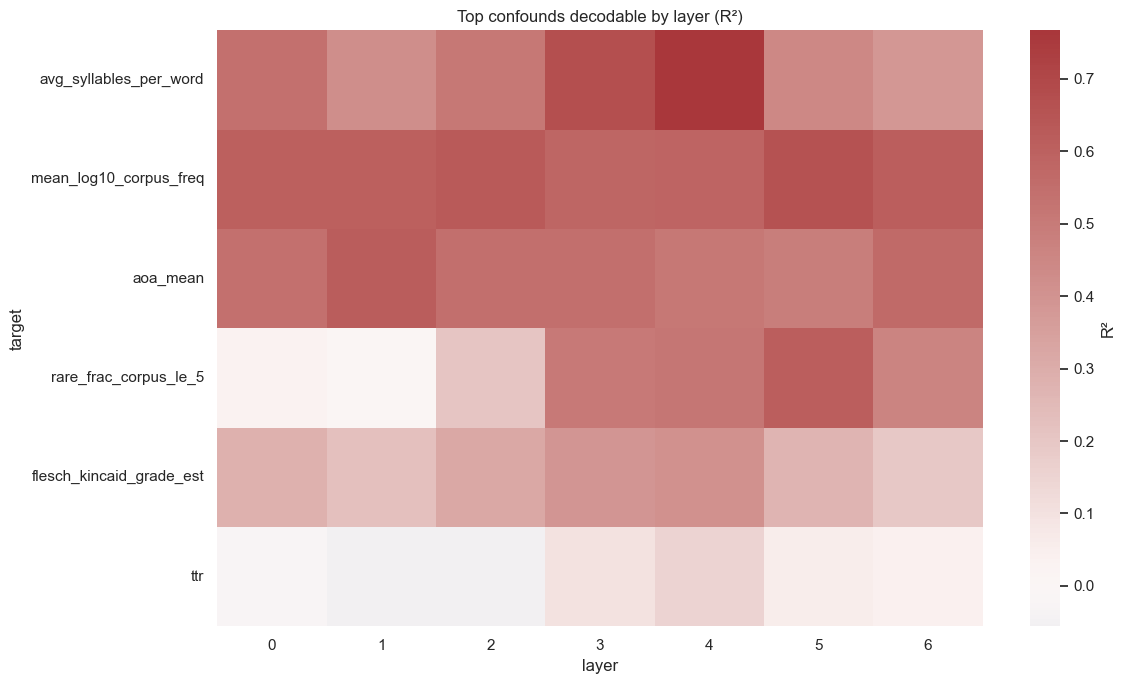

In [9]:
# Summaries: best age layer, confound peak layers, and per-layer correlations
age_best_layer = int(dfp.sort_values("accuracy", ascending=False).iloc[0]["layer"])
age_best_acc = float(dfp.sort_values("accuracy", ascending=False).iloc[0]["accuracy"])
print("best age layer:", age_best_layer, "acc=", age_best_acc)

if reg is None:
    print("No regression probes loaded.")
    raise SystemExit(0)

# Peak R2 layer per target
peak = (reg.sort_values("r2", ascending=False).groupby("target", as_index=False).first())
peak = peak.rename(columns={"layer":"confound_peak_layer","r2":"confound_peak_r2"})
peak = peak.sort_values("confound_peak_r2", ascending=False)
peak.head(15)

# Which confounds peak near the best age layer?
near = peak.assign(dist=lambda d: (d["confound_peak_layer"] - age_best_layer).abs())
near = near.sort_values(["dist","confound_peak_r2"], ascending=[True, False])
display(near.head(15))

# Per-layer correlation: corr(accuracy(layer), r2(layer)) for each target
corr_rows=[]
for t, g in reg.groupby("target"):
    gg = g.merge(dfp[["layer","accuracy"]], on="layer", how="inner")
    if len(gg) < 3: continue
    r = float(np.corrcoef(gg["accuracy"], gg["r2"])[0,1])
    corr_rows.append({"target": t, "corr_acc_r2": r, "max_r2": float(gg["r2"].max())})
corr = pd.DataFrame(corr_rows).sort_values(["corr_acc_r2","max_r2"], ascending=False)
corr.head(20)

# Heatmap: targets × layers (R2)
pv = reg.pivot_table(index="target", columns="layer", values="r2", aggfunc="mean")
pv = pv.loc[pv.max(axis=1).sort_values(ascending=False).head(25).index]  # top 25 targets
plt.figure(figsize=(12, 7))
sns.heatmap(pv, cmap="vlag", center=0, cbar_kws={"label":"R²"})
plt.title("Top confounds decodable by layer (R²)")
plt.xlabel("layer")
plt.ylabel("target")
plt.tight_layout()


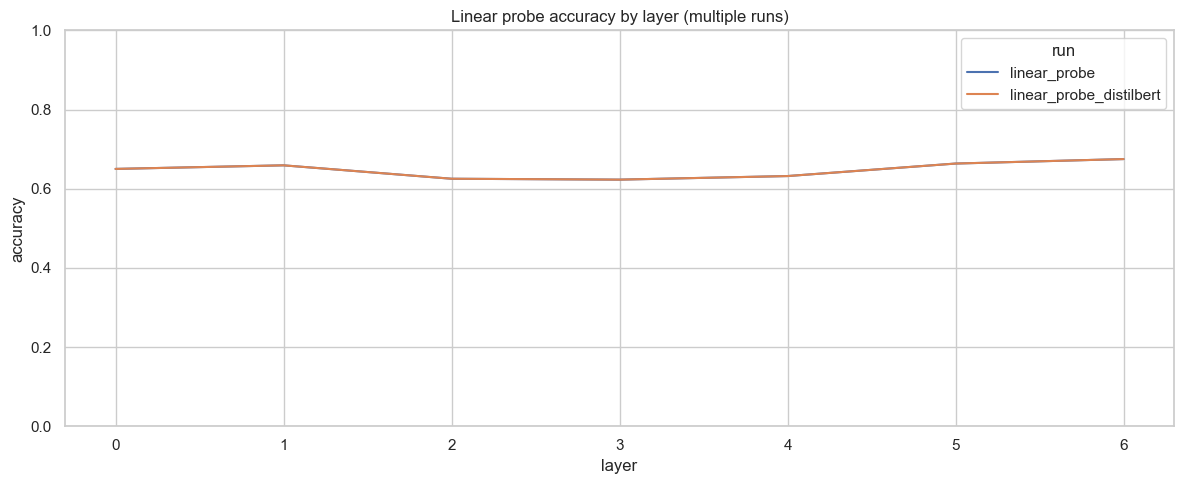

In [10]:
if len(linear_probe_csvs) > 1:
    runs=[]
    for p in linear_probe_csvs:
        d = pd.read_csv(p)
        # label by parent folder
        d['run'] = p.parent.name
        runs.append(d)
    allp = pd.concat(runs, ignore_index=True)
    plt.figure(figsize=(12,5))
    sns.lineplot(data=allp, x='layer', y='accuracy', hue='run')
    plt.title('Linear probe accuracy by layer (multiple runs)')
    plt.ylim(0,1)
    plt.tight_layout()
else:
    print('Only one probe_results.csv found.')


## Fine-Tuned Age Classifier

Load fine-tuned text age-classifier summaries and, if present, rewrite-evaluation summaries. These are **additional evaluators**, not replacements for the probe analysis.


In [ ]:
ft_summary_paths = sorted(ROOT.glob("results/analysis/natural_language/age_classifier/finetuned_age_classifier/**/summary.json"))
rewrite_eval_paths = sorted(ROOT.glob("results/analysis/natural_language/rewrite_evaluation/rewrite_eval/**/summary.json"))

print("fine-tuned classifier summaries:", len(ft_summary_paths))
for p in ft_summary_paths[:20]:
    print("  ", p)
print("rewrite eval summaries:", len(rewrite_eval_paths))
for p in rewrite_eval_paths[:20]:
    print("  ", p)

ft_rows = []
for p in ft_summary_paths:
    try:
        d = json.loads(p.read_text())
    except Exception:
        continue
    row = {"path": str(p), "run": p.parent.name}
    row.update({
        "model": d.get("model"),
        "n_items": d.get("n_items"),
        "age_cutoff": d.get("age_cutoff"),
        "val_accuracy": (d.get("val_metrics") or {}).get("accuracy"),
        "val_f1_macro": (d.get("val_metrics") or {}).get("f1_macro"),
        "val_roc_auc": (d.get("val_metrics") or {}).get("roc_auc"),
        "test_accuracy": (d.get("test_metrics") or {}).get("accuracy"),
        "test_f1_macro": (d.get("test_metrics") or {}).get("f1_macro"),
        "test_roc_auc": (d.get("test_metrics") or {}).get("roc_auc"),
    })
    ft_rows.append(row)
ft = pd.DataFrame(ft_rows)
display(ft.sort_values(["test_accuracy", "test_roc_auc"], ascending=False) if not ft.empty else ft)

rewrite_rows = []
for p in rewrite_eval_paths:
    try:
        d = json.loads(p.read_text())
    except Exception:
        continue
    row = {"path": str(p), "run": p.parent.name}
    row.update(d)
    rewrite_rows.append(row)
rewrite_eval = pd.DataFrame(rewrite_rows)
display(rewrite_eval.sort_values([c for c in ["mean_delta_age_prob", "mean_delta_aoa_p90", "mean_tfidf_cosine"] if c in rewrite_eval.columns], ascending=False) if not rewrite_eval.empty else rewrite_eval)


In [ ]:
if not ft.empty:
    probe_best_acc = float(dfp["accuracy"].max())
    compare = ft[["run", "model", "test_accuracy", "test_roc_auc"]].copy()
    compare["best_probe_accuracy"] = probe_best_acc
    display(compare.sort_values("test_accuracy", ascending=False))

    plt.figure(figsize=(10,4))
    plot_df = compare.melt(id_vars=["run", "model"], value_vars=["test_accuracy", "best_probe_accuracy"], var_name="metric", value_name="value")
    sns.barplot(data=plot_df, x="run", y="value", hue="metric")
    plt.title("Fine-tuned text classifier vs best embedding-probe accuracy")
    plt.ylim(0, 1)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
else:
    print("No fine-tuned classifier summaries found yet.")

if not rewrite_eval.empty:
    metrics = [c for c in ["mean_delta_age_prob", "mean_delta_aoa_mean", "mean_delta_aoa_p90", "mean_tfidf_cosine"] if c in rewrite_eval.columns]
    if metrics:
        plt.figure(figsize=(12,4))
        plot_df = rewrite_eval[["run"] + metrics].melt(id_vars="run", var_name="metric", value_name="value")
        sns.barplot(data=plot_df, x="run", y="value", hue="metric")
        plt.title("Rewrite evaluation summary")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
else:
        print("Rewrite evaluation summaries found, but no standard metrics columns are present.")
else:
    print("No rewrite evaluation summaries found yet.")
